In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

In [67]:
FILE_PATH = '../Used_Cars_Homework.csv'
data = pd.read_csv(FILE_PATH)

data.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,18479
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,38680
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,40016
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,19668
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,36190


In [68]:
data.shape

(300, 9)

In [69]:
data.dtypes

age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                   str
fuel_type               str
transmission            str
accident_history        str
price_azn             int64
dtype: object

In [70]:
data.isna().sum()

age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64

In [71]:
data.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [72]:
X = data.drop(columns=['price_azn'])
y = data['price_azn']

In [73]:
X

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no
1,10,74340.0,NaN,135,BMW,petrol,automatic,no
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no
...,...,...,...,...,...,...,...,...
295,8,103080.0,3.0,206,BMW,petrol,manual,no
296,3,27051.0,NaN,98,BMW,hybrid,automatic,no
297,1,18300.0,1.2,67,Kia,diesel,manual,no
298,11,170764.0,1.6,90,BMW,petrol,manual,no


In [74]:
y

0      16950
1      37335
2      30593
3      22641
4      41672
       ...  
295    46582
296    40510
297    26710
298    21582
299    36582
Name: price_azn, Length: 300, dtype: int64

In [75]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'bool', 'str']).columns.tolist()

In [76]:
numeric_features

['age_years', 'mileage_km', 'engine_l', 'power_hp']

In [77]:
categorical_features

['brand', 'fuel_type', 'transmission', 'accident_history']

In [78]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [80]:
reg = DecisionTreeRegressor(random_state=42, criterion='squared_error')

pipe = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('tree', reg)
    ]
)

param_grid = {
    'tree__max_depth': [3, 5, 7, None],
    'tree__min_samples_split': [2, 5, 10],
    'tree__min_samples_leaf': [1, 3, 5, 10],
}

In [81]:
cv = KFold(n_splits=5, random_state=42, shuffle=True)
grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
grid_search.best_params_

{'tree__max_depth': 7,
 'tree__min_samples_leaf': 3,
 'tree__min_samples_split': 10}

In [82]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_pred = best_model.predict(X_test)
print(f'''
Best params: {grid_search.best_params_}
RMSE: {rmse(y_test, y_pred):.3f}
R2: {r2_score(y_test, y_pred):.2f}
''')


Best params: {'tree__max_depth': 7, 'tree__min_samples_leaf': 3, 'tree__min_samples_split': 10}
RMSE: 4352.984
R2: 0.81



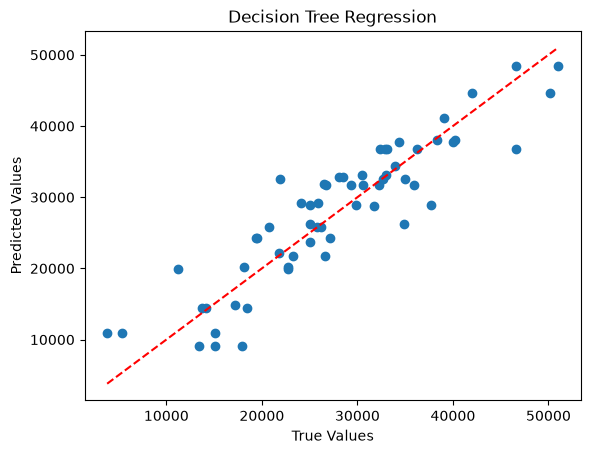

In [83]:
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.title('Decision Tree Regression')
high = max(y_test.max(), y_pred.max())
low = min(y_test.min(), y_pred.min())
plt.plot([low, high], [low, high], 'r--')
plt.show()